In [1]:
from pathlib import Path
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter

PROJECT_ROOT = Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "warehouse.duckdb"

conn = duckdb.connect(str(DB_PATH), read_only=True)

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# One fixed color per asset, used in every chart (and later in Power BI)
ASSET_COLORS = {
    "SPY":  "#2a78d6",  # blue
    "GLD":  "#eb6834",  # orange
    "DBC":  "#1baf7a",  # aqua
    "VNQ":  "#eda100",  # yellow
    "TIP":  "#e87ba4",  # magenta
    "TLT":  "#008300",  # green
    "CASH": "#6250d6",  # violet
}

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
})

In [3]:
conn.execute("SHOW TABLES").df()

,name
0,mart_asset_summary
1,mart_inflation
2,mart_monthly_returns
3,mart_regime_summary
4,stg_fred
5,stg_prices


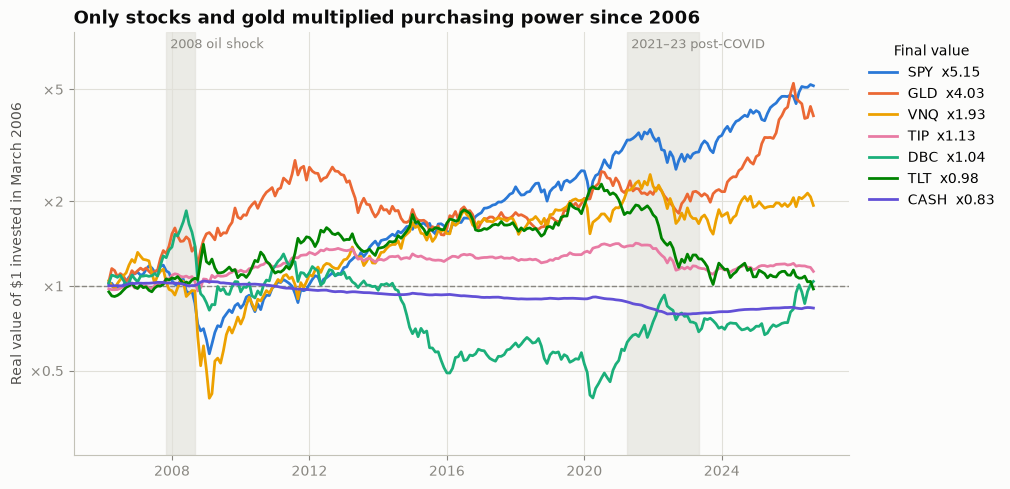

In [4]:
wealth = conn.execute("""
    SELECT 
        month, 
        ticker,
        real_wealth
    FROM mart_monthly_returns
""").df()

wealth_wide = wealth.pivot(index='month', columns='ticker', values='real_wealth')

final_values = wealth_wide.iloc[-1].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))

# High-inflation episodes
ax.axvspan(pd.Timestamp("2007-11-01"), pd.Timestamp("2008-09-01"), color=GRID, alpha=0.6)
ax.axvspan(pd.Timestamp("2021-04-01"), pd.Timestamp("2023-05-01"), color=GRID, alpha=0.6)
ax.text(pd.Timestamp("2007-11-01"), 7, " 2008 oil shock", color=MUTED, fontsize=9)
ax.text(pd.Timestamp("2021-04-01"), 7, " 2021–23 post-COVID", color=MUTED, fontsize=9)

# Break-even line: below it, the asset lost purchasing power
ax.axhline(1, color=MUTED, linewidth=1, linestyle="--")

# One line per asset, from best to worst, with its final value in the legend
for ticker, final_value in final_values.items():
    ax.plot(wealth_wide.index, wealth_wide[ticker],
            color=ASSET_COLORS[ticker], label=f"{ticker}  x{final_value:.2f}")

# Log scale with readable ticks
ax.set_yscale("log")
ax.set_ylim(0.25, 8)
ax.set_yticks([0.5, 1, 2, 5])
ax.set_yticklabels(["×0.5", "×1", "×2", "×5"])
ax.minorticks_off()

ax.set_title("Only stocks and gold multiplied purchasing power since 2006")
ax.set_ylabel("Real value of $1 invested in March 2006")
ax.legend(title="Final value", loc="upper left", bbox_to_anchor=(1.01, 1))

fig.savefig(FIGURES_DIR / "real_wealth.png", dpi=200, bbox_inches="tight")

### Findings: long-run real wealth (March 2006 – September 2026)

- **Only stocks and gold multiplied purchasing power.** $1 invested in SPY grew to ×5.15
  in real terms, and in GLD to ×4.03. Real estate (VNQ) roughly doubled (×1.93).
- **Three assets ended near or below their starting purchasing power:** inflation-linked
  bonds (TIP ×1.13) and commodities (DBC ×1.04) barely beat inflation, while long-term
  bonds (TLT ×0.98) and cash (×0.83) lost purchasing power over 20 years.
- **Commodities behave like insurance.** DBC protected purchasing power during the
  high-inflation episodes, but over the whole period it created almost no real wealth:
  the protection came at a high cost the rest of the time.
- **The path matters as much as the destination.** VNQ fell about 70% from its peak by
  early 2009, during the housing and financial crisis, and needed years to recover.


In [5]:
conn.execute("""
WITH lagged AS(
    SELECT regime,
    month,
    CASE WHEN regime = LAG(regime) OVER (ORDER BY month) THEN 0 ELSE 1 END AS flag
    FROM mart_inflation 
),

islands AS (
    SELECT 
        month,
        regime, 
        SUM(flag) OVER (ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) as grp
    FROM lagged
    WHERE flag IS NOT NULL
),

SELECT 
    grp,
    MIN(i.month) AS start,
    MAX(i.month) AS end,
    COUNT(*) AS n_months,
FROM islands AS i
WHERE i.regime = 'high'
GROUP BY grp
""").df()

,grp,start,end,n_months
0,15.0,2006-06-01,2006-07-01,2
1,47.0,2026-05-01,2026-05-01,1
2,13.0,2006-01-01,2006-01-01,1
3,21.0,2007-11-01,2008-02-01,4
4,23.0,2008-05-01,2008-09-01,5
5,45.0,2021-04-01,2023-05-01,26


In [6]:
conn.execute("""
WITH lagged AS(
    SELECT regime,
    month,
    CASE WHEN regime = LAG(regime) OVER (ORDER BY month) THEN 0 ELSE 1 END AS flag
    FROM mart_inflation 
),

islands AS (
    SELECT 
        month,
        regime, 
        SUM(flag) OVER (ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) as grp
    FROM lagged
    WHERE flag IS NOT NULL
),

SELECT 
    ticker,
    grp,
    EXP(SUM(LN(1 + m.real_return))) - 1 AS cumulative_real_return,
    MIN(i.month) AS start,
    MAX(i.month) AS end,
    COUNT(*) AS n_months,
FROM islands AS i
INNER JOIN mart_monthly_returns m
    ON i.month = m.month
WHERE i.regime = 'high'
GROUP BY ticker, grp
ORDER BY start 
""").df().pivot(index='ticker', columns='start', values='cumulative_real_return').round(3)

start,2006-06-01,2007-11-01,2008-05-01,2021-04-01,2026-05-01
ticker,,,,,
CASH,-0.000,-0.006,-0.016,-0.095,-0.002
DBC,0.005,0.193,-0.127,0.167,-0.057
GLD,-0.024,0.203,-0.040,-0.004,-0.020
SPY,-0.001,-0.144,-0.171,-0.051,0.048
TIP,0.011,0.076,-0.042,-0.157,-0.003
TLT,0.026,0.046,0.014,-0.304,0.001
VNQ,0.082,-0.191,-0.081,-0.185,-0.011


## High-inflation episodes

**Question:** are the 38 high-inflation months one continuous period or several separate episodes?
This matters because months within the same episode are not independent observations:
conclusions based on 38 months may really rest on only two or three historical events.

**Method:** consecutive months with the same regime are grouped into "islands"
(gaps-and-islands technique: flag each regime change with `LAG`, then number the islands
with a running `SUM`). Only the high-inflation islands are kept.

In [7]:
conn.execute("""
WITH lagged AS(
    SELECT regime,
    month,
    CASE WHEN regime = LAG(regime) OVER (ORDER BY month) THEN 0 ELSE 1 END AS flag
    FROM mart_inflation 
),

islands AS (
    SELECT 
        month,
        regime, 
        SUM(flag) OVER (ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) as grp
    FROM lagged
    WHERE flag IS NOT NULL
)

SELECT 
    ticker,
    grp,
    EXP(SUM(LN(1 + m.real_return))) - 1 AS cumulative_real_return,
    MIN(i.month) AS start,
    MAX(i.month) AS end,
    COUNT(*) AS n_months,
FROM islands AS i
INNER JOIN mart_monthly_returns m
    ON i.month = m.month
WHERE i.regime = 'high'
GROUP BY ticker, grp
ORDER BY start 
""").df()

,ticker,grp,cumulative_real_return,start,end,n_months
0,GLD,15.0,-0.024413,2006-06-01,2006-07-01,2
1,DBC,15.0,0.005332,2006-06-01,2006-07-01,2
2,TIP,15.0,0.011411,2006-06-01,2006-07-01,2
3,SPY,15.0,-0.000843,2006-06-01,2006-07-01,2
4,TLT,15.0,0.025519,2006-06-01,2006-07-01,2
5,VNQ,15.0,0.081855,2006-06-01,2006-07-01,2
6,CASH,15.0,-0.000175,2006-06-01,2006-07-01,2
7,GLD,21.0,0.203238,2007-11-01,2008-02-01,4
8,DBC,21.0,0.192993,2007-11-01,2008-02-01,4
9,SPY,21.0,-0.144402,2007-11-01,2008-02-01,4


**Result:** the 38 months form 5 islands:

| Start | End | Months |
|---|---|---|
| 2006-06 | 2006-07 | 2 |
| 2007-11 | 2008-02 | 4 |
| 2008-05 | 2008-09 | 5 |
| 2021-04 | 2023-05 | 26 |
| 2026-05 | 2026-05 | 1 |

**Interpretation:**
- The two 2008 islands are separated by only two months (March–April 2008), when YoY inflation
  dipped just below the 4% threshold. They are treated as a single episode: the 2007–08 oil shock.
- The 2021–23 island is the post-COVID inflation surge.
- The 2006 and 2026 islands are short spikes (1–2 months). Annualized returns over such short
  periods are dominated by noise, so they are excluded from the episode-level analysis.

This leaves two episodes for the analysis below: **2008 oil shock** (2007-11 → 2008-09, 11 months)
and **2021–23 post-COVID** (2021-04 → 2023-05, 26 months).

In [8]:
episode_returns = conn.execute("""
    WITH periods AS(
        SELECT
            month,
            CASE
                WHEN month BETWEEN DATE '2007-11-01' AND DATE '2008-09-01' THEN  '2008 oil shock'
                WHEN month BETWEEN DATE '2021-04-01' AND DATE '2023-05-01' THEN  '2021-23 post-COVID'
            END AS period,
            ticker,
            real_return
            FROM mart_monthly_returns 
    )

    SELECT
        ticker,
        period,
        EXP(SUM(LN(1 + real_return))) - 1 AS cumulative_real_return,
        COUNT(*) AS n_months
    FROM periods
    WHERE period IS NOT NULL
    GROUP BY ticker, period
""").df()

episode_returns



,ticker,period,cumulative_real_return,n_months
0,VNQ,2008 oil shock,-0.162507,11
1,TIP,2008 oil shock,0.008900,11
2,GLD,2008 oil shock,0.034152,11
3,CASH,2008 oil shock,-0.024768,11
4,DBC,2008 oil shock,0.088286,11
5,VNQ,2021-23 post-COVID,-0.184766,26
6,DBC,2021-23 post-COVID,0.166579,26
7,TIP,2021-23 post-COVID,-0.156516,26
8,GLD,2021-23 post-COVID,-0.004403,26
9,CASH,2021-23 post-COVID,-0.094881,26


In [9]:
episode_wide = episode_returns.pivot(index="ticker", columns="period", values="cumulative_real_return")

episode_wide = episode_wide[["2008 oil shock", "2021-23 post-COVID"]]
episode_wide = episode_wide.sort_values("2021-23 post-COVID")

episode_wide

period,2008 oil shock,2021-23 post-COVID
ticker,,
TLT,0.050919,-0.304363
VNQ,-0.162507,-0.184766
TIP,0.008900,-0.156516
CASH,-0.024768,-0.094881
SPY,-0.267971,-0.051148
GLD,0.034152,-0.004403
DBC,0.088286,0.166579


**Result:** cumulative real return of each asset over each episode.

**Interpretation:**
- **Commodities (DBC) were the only asset with positive real returns in both episodes**
  (+8.8% and +16.7%). In both cases, inflation was driven largely by energy and commodity prices.
- **Gold (GLD) preserved purchasing power but did not gain** (+3.4% and −0.4%).
  The regime-level average (+3% a year) overstated its protection.
- **Bonds depend on the type of episode.** Long-term Treasuries (TLT) gained +5.1% in 2008,
  acting as a safe haven during the financial crisis, but lost −30.4% in 2021–23 as interest rates
  rose sharply. Even inflation-linked bonds (TIP) lost −15.7%: they protect against inflation,
  not against the rate hikes used to fight it.
- **Equities (SPY) and real estate (VNQ) lost in both episodes.** SPY's −26.8% in 2008 is
  driven mostly by the start of the financial crisis; in 2021–23 the loss was much smaller (−5.1%).
- **Cash lost purchasing power in both episodes** (−2.5% and −9.5%).

**Limitation:** these conclusions rest on only two episodes, and the 2008 episode overlaps with
the 2008 financial crisis. They describe what happened, not a general rule.

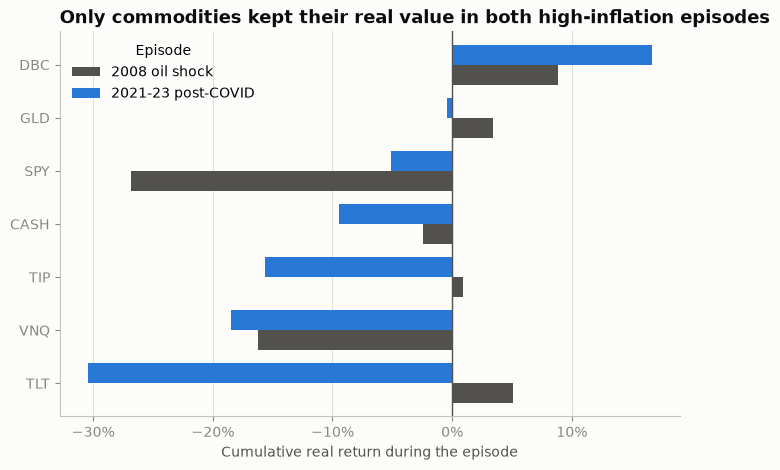

In [10]:
fig, ax = plt.subplots(figsize=(8,5))

episode_wide.plot.barh(ax=ax , color=[INK_SECONDARY, "#2a78d6"], width= 0.75)

ax.axvline(0, color=INK_SECONDARY, linewidth= 1)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))

ax.set_title("Only commodities kept their real value in both high-inflation episodes")
ax.set_xlabel("Cumulative real return during the episode")
ax.set_ylabel("")
ax.legend(title="Episode")

fig.savefig(FIGURES_DIR / "episode_returns.png", dpi=200, bbox_inches="tight")

### Findings: high-inflation episodes

- **Commodities (DBC) were the only asset with positive real returns in both episodes**
  (+8.8% in 2008 and +16.7% in 2021–23).
- **Gold (GLD) roughly preserved purchasing power** (+3.4% and −0.4%): it neither gained
  nor lost much.
- **Long-term bonds behaved very differently in each episode.** TLT gained +5.1% in 2008 but
  lost −30.4% in 2021–23, consistent with the sharp rise in interest rates in 2022: when rates
  rise, the price of existing long-term bonds falls. Inflation-linked bonds (TIP) also lost −15.7%.
- **Stocks (SPY) and real estate (VNQ) lost in both episodes.** SPY's −26.8% in 2008 overlaps
  with the start of the financial crisis; in 2021–23 its loss was much smaller (−5.1%).
- **Cash lost purchasing power in both episodes** (−2.5% and −9.5%).

In [11]:
asset_summary = conn.execute("""
    SELECT 
        ticker,
        real_cagr,
        max_real_drawdown
    FROM mart_asset_summary
""").df()

asset_summary

,ticker,real_cagr,max_real_drawdown
0,CASH,-0.008734,-0.237810
1,TIP,0.005815,-0.224623
2,TLT,-0.001184,-0.576096
3,SPY,0.082865,-0.515981
4,DBC,0.001809,-0.783860
5,GLD,0.070024,-0.457087
6,VNQ,0.032543,-0.696824


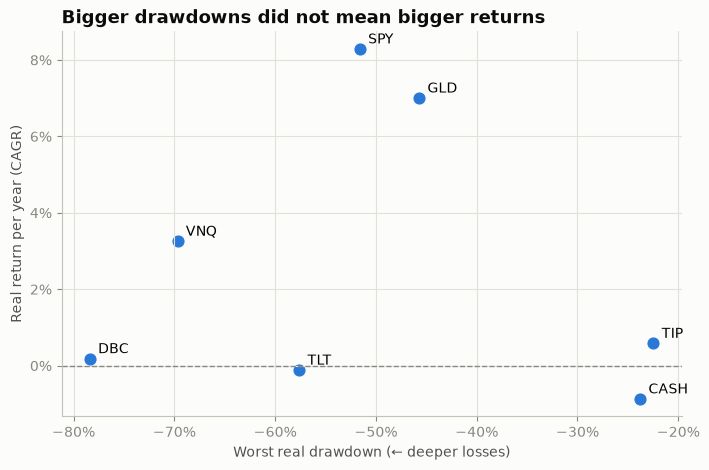

In [12]:
fig, ax = plt.subplots(figsize= (8,5))

ax.scatter(asset_summary['max_real_drawdown'], asset_summary['real_cagr'], 
           color="#2a78d6", s=60)

ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")

for ticker, cagr, drawdown in zip(asset_summary['ticker'],asset_summary['real_cagr'],asset_summary['max_real_drawdown']):
    ax.annotate(ticker, xy=(drawdown,cagr), xytext=(6,4), textcoords="offset points")

ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

ax.set_title("Bigger drawdowns did not mean bigger returns")
ax.set_ylabel("Real return per year (CAGR)")
ax.set_xlabel("Worst real drawdown (← deeper losses)")

fig.savefig(FIGURES_DIR / "return_vs_drawdown.png", dpi=200, bbox_inches="tight")

### Findings: return vs. risk

- **The best real returns came with large drawdowns.** SPY earned about 8.3% per year in
  real terms and GLD about 7.0%, but at their worst they lost 52% and 46% of their real value.
- **Larger drawdowns were not rewarded with higher returns.** The two assets with the deepest
  drawdowns, DBC (−78%) and VNQ (−70%), delivered only about 0.2% and 3.2% per year.
- **Lower-risk assets barely kept up with inflation.** TIP and cash had the smallest
  drawdowns (about −22% and −24%), but returned about 0.6% and −0.9% per year.
- **Conclusion:** taking more risk did not guarantee more return, and no asset delivered
  strong real returns without deep drawdowns along the way.
    